# Практическое занятие: Настройка нейронов и сравнение активаций

**Цель работы**: Научиться подбирать веса и смещения нейронов, понять влияние функции активации на классификацию, а также убедиться, что двухслойная сеть может решать нелинейные задачи.

**План**:
1. Импорт библиотек и вспомогательные функции.
2. Задание 1: Однослойный нейрон для OR.
3. Задание 2: Сравнение функций активации на задаче AND.
4. Задание 3: Двухслойная сеть для прямоугольной области.
5. Анализ результатов.

---

> **Выполнил:** Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ.
>
> Все три задания выполнены. Тетрадка выполняется целиком без интерактивности: подобранные значения весов заданы в
> коде явно и подставлены в положения ползунков `ipywidgets` (виджеты оставлены — в запущенном Jupyter их можно
> двигать), а после каждого виджета та же функция вызвана ещё раз обычным образом, поэтому графики и точность
> сохраняются в файле статично и видны при любом просмотре. Ответы на вопросы — в ячейках сразу после вопросов;
> часть ответов подкреплена небольшими расчётами. Нейросети здесь не обучаются (всё на `numpy`), поэтому
> отдельная ячейка выбора устройства не нужна.

In [1]:
# Импортируем всё необходимое
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, HBox, VBox, widgets
import networkx as nx

%matplotlib inline

In [2]:
# Функции активации и их производные (для справки)
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

def step(x):
    return (x >= 0).astype(int)

## Задание 1. Один нейрон для OR

Напомним таблицу истинности OR:

| x1 | x2 | y |
|----|----|---|
| 0  | 0  | 0 |
| 0  | 1  | 1 |
| 1  | 0  | 1 |
| 1  | 1  | 1 |

Используя ступенчатую функцию активации, подберите вес $w_1$, $w_2$ и смещение $b$ так, чтобы нейрон правильно классифицировал все четыре точки: на графике ниже синие точки должны оказаться в синей области, а красные точки - в красной области.

**Инструкция**: двигайте ползунки и следите за точностью. При точности 100% вы нашли решение.
Обязательно перед отправкой (публикацией) блокнота убедитесь, что ваш выбор в ползунках и на графике сохраняется. Если нет - напишите прямо текстом ответ.

In [3]:
# Найденное решение (ползунки ниже стоят в этом положении)
W1_OR, W2_OR, B_OR = 1.0, 1.0, -0.5

# Данные для OR
X_or = np.array([[0,0],[0,1],[1,0],[1,1]])
y_or = np.array([0,1,1,1])

def plot_or_neuron(w1, w2, b):
    # Сетка для визуализации
    xx, yy = np.meshgrid(np.linspace(-0.5,1.5,200),
                         np.linspace(-0.5,1.5,200))
    z = w1*xx + w2*yy + b
    a = step(z)

    plt.figure(figsize=(12,4))

    # 1. Карта классификации
    plt.subplot(1,2,1)
    plt.contourf(xx, yy, a, levels=[-0.5,0.5,1.5], colors=['blue','red'], alpha=0.5)
    plt.scatter(X_or[y_or==0,0], X_or[y_or==0,1], color='blue', s=200, label='0', edgecolor='k')
    plt.scatter(X_or[y_or==1,0], X_or[y_or==1,1], color='red', s=200, label='1', edgecolor='k')
    plt.xlim(-0.5,1.5)
    plt.ylim(-0.5,1.5)
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.title('Классификация нейроном')
    plt.legend()
    plt.grid(True)

    # 2. Точность
    z_vals = w1*X_or[:,0] + w2*X_or[:,1] + b
    pred = step(z_vals)
    acc = np.mean(pred == y_or)

    plt.subplot(1,2,2)
    plt.axis('off')
    plt.text(0.5,0.5, f'Точность: {acc*100:.1f}%', fontsize=20, ha='center')
    if acc == 1.0:
        plt.text(0.5,0.3, '✓ Решение найдено!', fontsize=16, color='green', ha='center')
    else:
        plt.text(0.5,0.3, 'Продолжайте подбор', fontsize=16, color='gray', ha='center')

    plt.show()

interact(plot_or_neuron,
         w1=FloatSlider(min=-2, max=2, step=0.1, value=W1_OR, description='w1'),
         w2=FloatSlider(min=-2, max=2, step=0.1, value=W2_OR, description='w2'),
         b=FloatSlider(min=-2, max=2, step=0.1, value=B_OR, description='b'));

interactive(children=(FloatSlider(value=1.0, description='w1', max=2.0, min=-2.0), FloatSlider(value=1.0, desc…

**Выбранные значения в задании 1:** $w_1 = 1{,}0$, $w_2 = 1{,}0$, $b = -0{,}5$. Тот же график без виджета (сохраняется статично):

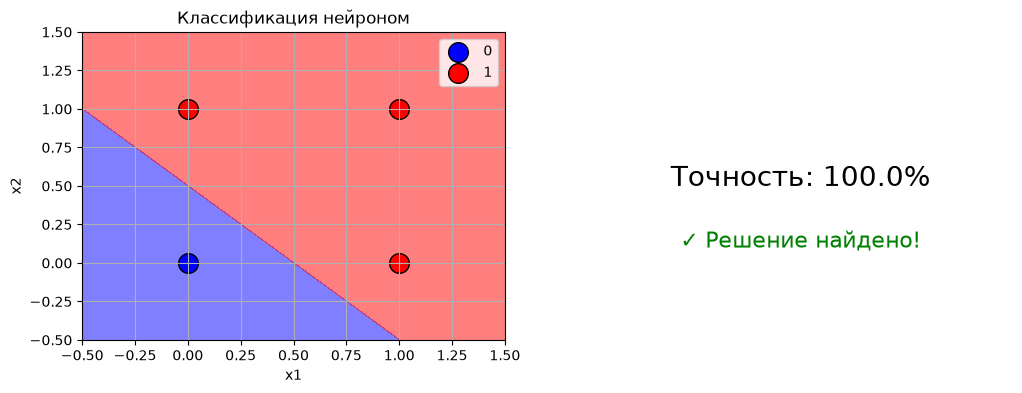

In [4]:
plot_or_neuron(W1_OR, W2_OR, B_OR)

In [5]:
# Сколько вообще решений на сетке ползунков (шаг 0.1)? Перебор всех 41^3 комбинаций
grid = np.round(np.arange(-2, 2.01, 0.1), 1)
sols = [(a, c, d) for a in grid for c in grid for d in grid
        if np.all(step(a * X_or[:, 0] + c * X_or[:, 1] + d) == y_or)]
print(f"решений на сетке: {len(sols)} из {len(grid)**3}")
print("все решения удовлетворяют условиям b < 0, w1 + b >= 0, w2 + b >= 0:",
      all(d < 0 and a + d >= 0 and c + d >= 0 for a, c, d in sols))

# Что происходит при уменьшении смещения (w1 = w2 = 1)
for b_try in [-0.5, -1.0, -1.5, -2.0, -5.0]:
    pred = step(X_or[:, 0] + X_or[:, 1] + b_try)
    print(f"b = {b_try:5}: выходы {pred.tolist()}, точность {np.mean(pred == y_or) * 100:.0f} %")

решений на сетке: 2870 из 68921
все решения удовлетворяют условиям b < 0, w1 + b >= 0, w2 + b >= 0: True
b =  -0.5: выходы [0, 1, 1, 1], точность 100 %
b =  -1.0: выходы [0, 1, 1, 1], точность 100 %
b =  -1.5: выходы [0, 0, 0, 1], точность 50 %
b =  -2.0: выходы [0, 0, 0, 1], точность 50 %
b =  -5.0: выходы [0, 0, 0, 0], точность 25 %


**Вопрос**: Почему выбранные вами значения работают? Что произойдёт, если сделать смещение очень большим отрицательным числом?

**Почему выбранные значения работают.** Нейрон выдаёт 1, если $w_1 x_1 + w_2 x_2 + b \ge 0$. При $w_1 = w_2 = 1$, $b = -0{,}5$:
- (0, 0): $z = -0{,}5 < 0$ → 0;
- (0, 1) и (1, 0): $z = 0{,}5 \ge 0$ → 1;
- (1, 1): $z = 1{,}5$ → 1.

Граница $x_1 + x_2 = 0{,}5$ отрезает от квадрата только угол (0, 0), точность 100 %.

В общем виде OR требует трёх условий:
- $b < 0$, иначе (0, 0) даст 1;
- $w_1 + b \ge 0$ и $w_2 + b \ge 0$, иначе (1, 0) или (0, 1) дадут 0.

Тогда условие для (1, 1), $w_1 + w_2 + b \ge 0$, выполняется автоматически. Перебор сетки ползунков с шагом 0,1 нашёл 2870 решений из 68 921, и все они удовлетворяют этим условиям. То есть решение не единственное: это целая область параметров.

**Очень большое отрицательное смещение** сдвигает границу вверх-вправо, и нейрон начинает выдавать 0 там, где нужна 1. При $w_1 = w_2 = 1$:
- $b = -0{,}5$ и $-1$: OR, точность 100 %. При $b = -1$ точки (0, 1) и (1, 0) лежат ровно на границе ($z = 0$), и спасает только нестрогое неравенство в ступенчатой функции.
- $b = -1{,}5$ и $-2$: выходы [0, 0, 0, 1] — нейрон реализует уже AND, точность 50 %.
- $b = -5$: всегда 0, точность 25 % (верна только точка (0, 0)).

Смещение работает как порог срабатывания: чем оно отрицательнее, тем больше входов должно быть «включено», чтобы нейрон сработал.

## Задание 2. Сравнение функций активации с численными метриками

Теперь посмотрим, как разные функции активации влияют на поведение нейрона. Возьмём задачу AND (таблица ниже) и один нейрон. Будем использовать три активации: сигмоиду, гиперболический тангенс (tanh) и ReLU. Для каждой активации построим карту отклика, столбчатую диаграмму значений на точках и вычислим метрики:
- **Точность** (если порог 0.5)
- **Средняя активация для класса 0** (чем ближе к 0, тем лучше)
- **Средняя активация для класса 1** (чем ближе к 1, тем лучше)
- **Разность средних** (margin, чем больше, тем лучше разделение)
- **Среднеквадратичная ошибка (MSE)** между выходом и целевым значением

**Таблица AND**:
| x1 | x2 | y |
|----|----|---|
| 0  | 0  | 0 |
| 0  | 1  | 0 |
| 1  | 0  | 0 |
| 1  | 1  | 1 |

Подберите параметры так, чтобы нейрон правильно классифицировал точки, и сравните метрики для разных активаций.

In [6]:
# Выбранные параметры (обоснование — в ячейках ниже); ползунки стоят в этом положении
W1_AND, W2_AND, B_AND = 1.5, 1.5, -2.0

# Данные для AND
X_and = np.array([[0,0],[0,1],[1,0],[1,1]])
y_and = np.array([0,0,0,1])

def compute_metrics(activation_fn, X, y, w1, w2, b, scale_to_01=False):
    z = w1*X[:,0] + w2*X[:,1] + b
    a = activation_fn(z)
    if scale_to_01:  # для tanh масштабируем в [0,1] для единообразия метрик
        a = (a + 1)/2
    # Точность при пороге 0.5
    pred = (a >= 0.5).astype(int)
    acc = np.mean(pred == y)
    # Средние для классов
    mean_0 = np.mean(a[y==0])
    mean_1 = np.mean(a[y==1])
    margin = mean_1 - mean_0
    # MSE
    mse = np.mean((a - y)**2)
    return acc, mean_0, mean_1, margin, mse, a

def compare_activations_with_metrics(w1, w2, b):
    # Вычисляем выход для разных активаций на точках данных и на сетке
    xx, yy = np.meshgrid(np.linspace(-0.5,1.5,200),
                         np.linspace(-0.5,1.5,200))
    z_grid = w1*xx + w2*yy + b

    # Сигмоида
    a_sig_grid = sigmoid(z_grid)
    acc_sig, m0_sig, m1_sig, marg_sig, mse_sig, a_sig = compute_metrics(sigmoid, X_and, y_and, w1, w2, b)

    # Tanh (масштабируем в [0,1] для сравнения)
    a_tanh_grid = (tanh(z_grid) + 1)/2
    acc_tanh, m0_tanh, m1_tanh, marg_tanh, mse_tanh, a_tanh = compute_metrics(tanh, X_and, y_and, w1, w2, b, scale_to_01=True)

    # ReLU (для метрик используем исходный, для сетки нормируем для наглядности)
    a_relu_grid = relu(z_grid)
    a_relu_grid_norm = a_relu_grid / (np.max(a_relu_grid) + 1e-8)
    acc_relu, m0_relu, m1_relu, marg_relu, mse_relu, a_relu = compute_metrics(relu, X_and, y_and, w1, w2, b, scale_to_01=False)

    # Создаём фигуру с 3 строками и 3 столбцами
    fig, axes = plt.subplots(3, 3, figsize=(16, 12))

    # Строка 1: Сигмоида
    # Карта
    ax = axes[0,0]
    im = ax.contourf(xx, yy, a_sig_grid, levels=20, cmap='RdBu', alpha=0.7)
    plt.colorbar(im, ax=ax)
    ax.scatter(X_and[y_and==0,0], X_and[y_and==0,1], color='blue', s=100, label='0', edgecolor='k')
    ax.scatter(X_and[y_and==1,0], X_and[y_and==1,1], color='red', s=100, label='1', edgecolor='k')
    ax.set_xlim(-0.5,1.5); ax.set_ylim(-0.5,1.5)
    ax.set_xlabel('x1'); ax.set_ylabel('x2')
    ax.set_title('Сигмоида')
    ax.grid(True)

    # Столбцы
    ax = axes[0,1]
    colors = ['blue' if y == 0 else 'red' for y in y_and]
    ax.bar(range(4), a_sig, color=colors, edgecolor='k')
    ax.axhline(0.5, color='gray', linestyle='--')
    ax.set_xticks(range(4))
    ax.set_xticklabels([f'({x[0]},{x[1]})' for x in X_and], rotation=45)
    ax.set_ylabel('Выход')
    ax.set_title('Значения на точках')
    ax.set_ylim(-0.1, 1.1)

    # Метрики
    ax = axes[0,2]
    ax.axis('off')
    metrics_text = f"""Сигмоида:
    Точность: {acc_sig*100:.1f}%
    Среднее (класс 0): {m0_sig:.3f}
    Среднее (класс 1): {m1_sig:.3f}
    Разность средних: {marg_sig:.3f}
    MSE: {mse_sig:.3f}"""
    ax.text(0.1, 0.5, metrics_text, fontsize=12, fontfamily='monospace', verticalalignment='center')

    # Строка 2: Tanh
    ax = axes[1,0]
    im = ax.contourf(xx, yy, a_tanh_grid, levels=20, cmap='RdBu', alpha=0.7)
    plt.colorbar(im, ax=ax)
    ax.scatter(X_and[y_and==0,0], X_and[y_and==0,1], color='blue', s=100, label='0', edgecolor='k')
    ax.scatter(X_and[y_and==1,0], X_and[y_and==1,1], color='red', s=100, label='1', edgecolor='k')
    ax.set_xlim(-0.5,1.5); ax.set_ylim(-0.5,1.5)
    ax.set_xlabel('x1'); ax.set_ylabel('x2')
    ax.set_title('Tanh (масштабированный в [0,1])')
    ax.grid(True)

    ax = axes[1,1]
    colors = ['blue' if y == 0 else 'red' for y in y_and]
    ax.bar(range(4), a_tanh, color=colors, edgecolor='k')
    ax.axhline(0.5, color='gray', linestyle='--')
    ax.set_xticks(range(4))
    ax.set_xticklabels([f'({x[0]},{x[1]})' for x in X_and], rotation=45)
    ax.set_ylabel('Выход')
    ax.set_title('Значения на точках')
    ax.set_ylim(-0.1, 1.1)

    ax = axes[1,2]
    ax.axis('off')
    metrics_text = f"""Tanh (масшт.):
    Точность: {acc_tanh*100:.1f}%
    Среднее (класс 0): {m0_tanh:.3f}
    Среднее (класс 1): {m1_tanh:.3f}
    Разность средних: {marg_tanh:.3f}
    MSE: {mse_tanh:.3f}"""
    ax.text(0.1, 0.5, metrics_text, fontsize=12, fontfamily='monospace', verticalalignment='center')

    # Строка 3: ReLU
    ax = axes[2,0]
    im = ax.contourf(xx, yy, a_relu_grid_norm, levels=20, cmap='RdBu', alpha=0.7)
    plt.colorbar(im, ax=ax)
    ax.scatter(X_and[y_and==0,0], X_and[y_and==0,1], color='blue', s=100, label='0', edgecolor='k')
    ax.scatter(X_and[y_and==1,0], X_and[y_and==1,1], color='red', s=100, label='1', edgecolor='k')
    ax.set_xlim(-0.5,1.5); ax.set_ylim(-0.5,1.5)
    ax.set_xlabel('x1'); ax.set_ylabel('x2')
    ax.set_title('ReLU (нормированная карта)')
    ax.grid(True)

    ax = axes[2,1]
    colors = ['blue' if y == 0 else 'red' for y in y_and]
    ax.bar(range(4), a_relu, color=colors, edgecolor='k')
    ax.axhline(0.5, color='gray', linestyle='--')
    ax.set_xticks(range(4))
    ax.set_xticklabels([f'({x[0]},{x[1]})' for x in X_and], rotation=45)
    ax.set_ylabel('Выход (исходный)')
    ax.set_title('Значения на точках (ReLU)')
    ax.set_ylim(min(-0.1, a_relu.min()-0.1), max(1.5, a_relu.max()+0.1))

    ax = axes[2,2]
    ax.axis('off')
    metrics_text = f"""ReLU (исходный):
    Точность: {acc_relu*100:.1f}%
    Среднее (класс 0): {m0_relu:.3f}
    Среднее (класс 1): {m1_relu:.3f}
    Разность средних: {marg_relu:.3f}
    MSE: {mse_relu:.3f}"""
    ax.text(0.1, 0.5, metrics_text, fontsize=12, fontfamily='monospace', verticalalignment='center')

    plt.tight_layout()
    plt.show()

interact(compare_activations_with_metrics,
         w1=FloatSlider(min=-2, max=2, step=0.1, value=W1_AND, description='w1'),
         w2=FloatSlider(min=-2, max=2, step=0.1, value=W2_AND, description='w2'),
         b=FloatSlider(min=-2, max=2, step=0.1, value=B_AND, description='b'));

interactive(children=(FloatSlider(value=1.5, description='w1', max=2.0, min=-2.0), FloatSlider(value=1.5, desc…

Тот же результат без виджета (видно и при просмотре файла):

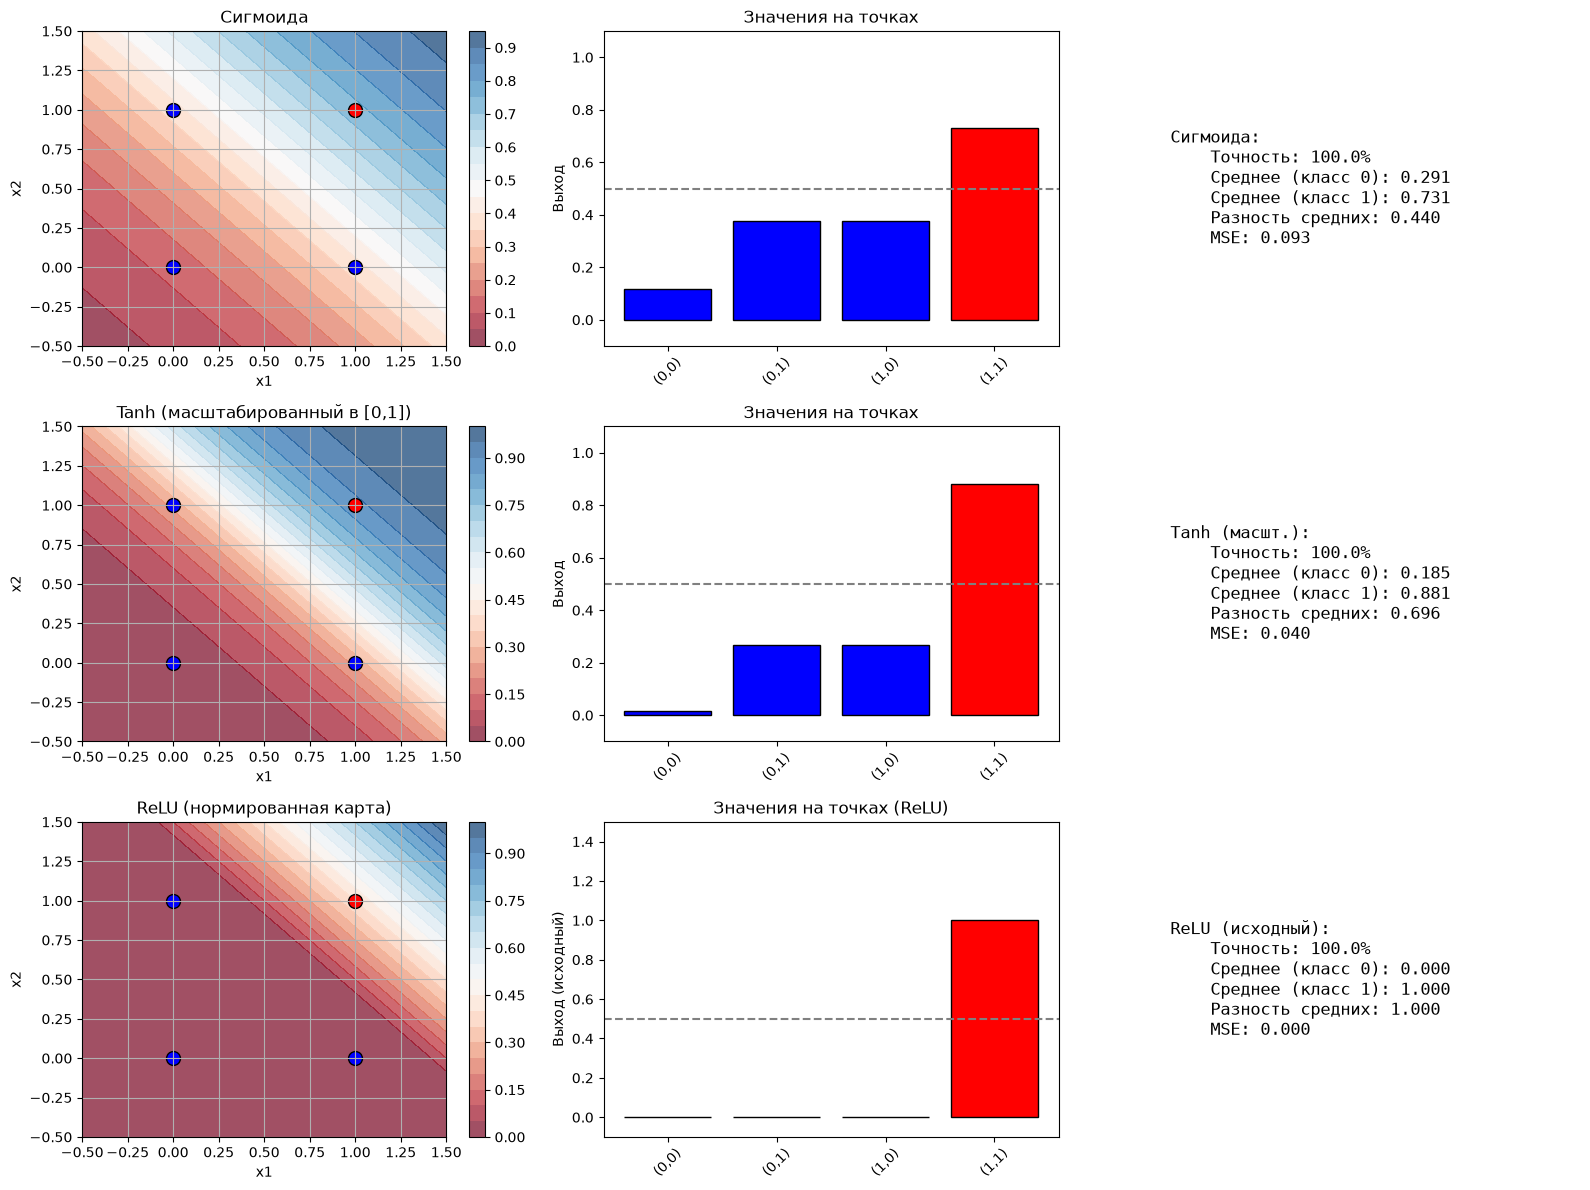

In [7]:
compare_activations_with_metrics(W1_AND, W2_AND, B_AND)

In [8]:
# Почему выбраны именно эти параметры: перебор всей сетки ползунков (шаг 0.1)
import pandas as pd

acts = {"Сигмоида": (sigmoid, False), "Tanh (масшт.)": (tanh, True), "ReLU": (relu, False)}
rows = []
for a in grid:
    for c in grid:
        for d in grid:
            r = {"w1": a, "w2": c, "b": d}
            ok = True
            for name, (fn, sc) in acts.items():
                acc, m0, m1, marg, mse, _ = compute_metrics(fn, X_and, y_and, a, c, d, scale_to_01=sc)
                r[f"acc {name}"], r[f"margin {name}"], r[f"MSE {name}"] = acc, marg, mse
                ok &= acc == 1.0
            r["все 100%"] = ok
            rows.append(r)
res = pd.DataFrame(rows)
good = res[res["все 100%"]]
print(f"наборов, при которых все три активации дают 100 %: {len(good)} из {len(res)}")
best = good.assign(mse_sum=good[[f"MSE {n}" for n in acts]].sum(axis=1)).sort_values("mse_sum").head(5)
pd.set_option("display.width", 200)
print("\nлучшие по суммарной MSE:")
print(best[["w1", "w2", "b"] + [f"margin {n}" for n in acts] + [f"MSE {n}" for n in acts]].round(3).to_string(index=False))

print("\nДля сравнения — параметры по умолчанию (1, 1, -1.5):")
for name, (fn, sc) in acts.items():
    acc, m0, m1, marg, mse, _ = compute_metrics(fn, X_and, y_and, 1.0, 1.0, -1.5, scale_to_01=sc)
    print(f"  {name:14s} точность {acc:.0%}, margin {marg:.3f}, MSE {mse:.3f}")

наборов, при которых все три активации дают 100 %: 539 из 68921

лучшие по суммарной MSE:
 w1  w2    b  margin Сигмоида  margin Tanh (масшт.)  margin ReLU  MSE Сигмоида  MSE Tanh (масшт.)  MSE ReLU
1.5 1.4 -2.0            0.427                 0.685          0.9         0.091              0.037     0.003
1.4 1.5 -2.0            0.427                 0.685          0.9         0.091              0.037     0.003
1.5 1.5 -2.0            0.440                 0.696          1.0         0.093              0.040     0.000
1.6 1.3 -2.0            0.427                 0.683          0.9         0.092              0.039     0.002
1.3 1.6 -2.0            0.427                 0.683          0.9         0.092              0.039     0.002

Для сравнения — параметры по умолчанию (1, 1, -1.5):
  Сигмоида       точность 100%, margin 0.310, MSE 0.115
  Tanh (масшт.)  точность 100%, margin 0.536, MSE 0.055
  ReLU           точность 100%, margin 0.500, MSE 0.062


**Вопросы**:
1. Какая активация даёт наибольшую разность средних (margin)? Что это означает?
2. Почему у ReLU среднее для класса 0 может быть не нулевым?
3. Как изменение смещения влияет на MSE?

ReLU, b = -2.0: выходы [0.0, 0.0, 0.0, 1.0], среднее для класса 0 = 0.000
ReLU, b = -1.0: выходы [0.0, 0.5, 0.5, 2.0], среднее для класса 0 = 0.333
ReLU, b = -0.5: выходы [0.0, 1.0, 1.0, 2.5], среднее для класса 0 = 0.667


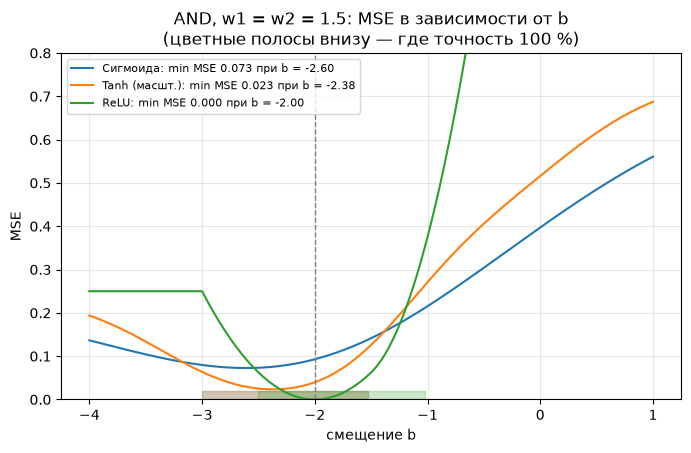

In [9]:
# К вопросам 2 и 3: среднее ReLU для класса 0 и зависимость MSE от смещения (w1 = w2 = 1.5)
for b_try in [-2.0, -1.0, -0.5]:
    _, m0, m1, marg, mse, a = compute_metrics(relu, X_and, y_and, 1.5, 1.5, b_try)
    print(f"ReLU, b = {b_try}: выходы {np.round(a, 2).tolist()}, среднее для класса 0 = {m0:.3f}")

bs = np.linspace(-4, 1, 201)
plt.figure(figsize=(8, 4.5))
for name, (fn, sc) in acts.items():
    mses = [compute_metrics(fn, X_and, y_and, 1.5, 1.5, bb, scale_to_01=sc)[4] for bb in bs]
    accs = np.array([compute_metrics(fn, X_and, y_and, 1.5, 1.5, bb, scale_to_01=sc)[0] for bb in bs])
    line, = plt.plot(bs, mses, label=f"{name}: min MSE {min(mses):.3f} при b = {bs[int(np.argmin(mses))]:.2f}")
    plt.fill_between(bs, 0, 0.02, where=accs == 1.0, color=line.get_color(), alpha=0.25, step="mid")
plt.axvline(-2.0, color="gray", ls="--", lw=1)
plt.xlabel("смещение b"); plt.ylabel("MSE"); plt.ylim(0, 0.8); plt.grid(True, alpha=0.3); plt.legend(fontsize=8)
plt.title("AND, w1 = w2 = 1.5: MSE в зависимости от b\n(цветные полосы внизу — где точность 100 %)")
plt.show()

Выбраны параметры $w_1 = w_2 = 1{,}5$, $b = -2$. Перебор сетки показал, что 100 % на всех трёх активациях дают 539 наборов из 68 921. Выбранный набор — один из лучших среди них по MSE, у ReLU MSE ровно 0.

| активация | среднее, класс 0 | среднее, класс 1 | margin | MSE |
|---|---|---|---|---|
| сигмоида | 0,291 | 0,731 | 0,440 | 0,093 |
| tanh, масштабированный в [0, 1] | 0,185 | 0,881 | 0,696 | 0,040 |
| ReLU | 0,000 | 1,000 | 1,000 | 0,000 |

**1. Наибольший margin даёт ReLU** (1,0), за ней tanh (0,70) и сигмоида (0,44). Margin — это разность средних выходов двух классов. Чем он больше, тем дальше друг от друга значения классов и тем меньше вероятность, что небольшое изменение входа или весов перекинет точку через порог 0,5.

У сигмоиды при тех же $z$ выходы ближе к 0,5: на точках (0, 1) и (1, 0) — 0,38, на (1, 1) — 0,73. Её наклон в нуле равен 1/4, у масштабированного tanh — 1/2, а ReLU линейна с наклоном 1 при $z > 0$ и даёт ровно 0 при $z \le 0$.

Оговорка: ReLU не ограничена сверху. Её margin вырос бы и сам по себе при больших весах, поэтому сравнивать margin разных активаций корректно только при одинаковых весах, как здесь.

**2. Среднее ReLU для класса 0 ненулевое**, если хотя бы для одной точки класса 0 $z > 0$. ReLU обнуляет только отрицательные $z$, а положительные пропускает как есть. При $w_1 = w_2 = 1{,}5$:
- $b = -2$: на точках (0, 1) и (1, 0) $z = -0{,}5$, выход 0, среднее 0;
- $b = -1$: выход на этих точках 0,5, среднее для класса 0 — 0,333;
- $b = -0{,}5$: выход 1,0, среднее 0,667.

Сигмоида и tanh вообще никогда не выдают ровно 0, поэтому у них среднее для класса 0 всегда больше нуля.

**3. Влияние смещения на MSE** (график MSE(b) при $w_1 = w_2 = 1{,}5$). У каждой активации MSE имеет минимум по $b$:
- сигмоида — 0,073 при $b = -2{,}60$;
- tanh — 0,023 при $b = -2{,}38$;
- ReLU — 0,000 при $b = -2{,}00$.

Слишком большое $b$ поднимает выходы класса 0. Быстрее всего MSE растёт у ReLU, потому что её выходы ничем не ограничены. Слишком маленькое $b$ опускает выход для (1, 1). У ReLU при $b \le -3$ все выходы нулевые, и MSE постоянна: 0,25 — это ошибка только на точке (1, 1).

Минимум MSE не совпадает с серединой интервала, где точность 100 %. У сигмоиды и tanh он сдвинут к более отрицательным $b$: ошибка на трёх точках класса 0 весит втрое больше, чем на одной точке класса 1.

## Задание 3. Двухслойная сеть для прямоугольной области

Рассмотрим задачу, где класс 1 — это точки, у которых обе координаты больше 0.3, а класс 0 — все остальные. Для наглядности возьмём девять точек с координатами 0, 0.5 и 1:

- (0,0): 0
- (0,0.5): 0
- (0,1): 0
- (0.5,0): 0
- (0.5,0.5): 1
- (0.5,1): 1
- (1,0): 0
- (1,0.5): 1
- (1,1): 1

Эта задача не решается одним нейроном (почему?), но двухслойная сеть с двумя нейронами в скрытом слое справится. Один нейрон должен определять условие $x_1 > 0.3$, второй — $x_2 > 0.3$, а выходной нейрон — логическое AND этих двух условий.

Используя ступенчатую активацию, подберите веса и смещения так, чтобы сеть правильно классифицировала все девять точек.

**Перед отправкой блокнота убедитесь, что положения слайдеров и графики сохранились, иначе сделайте снимок результирующего состояния.**


In [10]:
# Найденное решение (ползунки ниже стоят в этом положении):
# h1 = [x1 - 0.3 >= 0],  h2 = [x2 - 0.3 >= 0],  y = [h1 + h2 - 1.5 >= 0]
SOL = dict(w11=1.0, w12=0.0, b1=-0.3, w21=0.0, w22=1.0, b2=-0.3, wo1=1.0, wo2=1.0, bo=-1.5)

# Данные для прямоугольной области
X_rect = np.array([[0,0], [0,0.5], [0,1], [0.5,0], [0.5,0.5], [0.5,1], [1,0], [1,0.5], [1,1]])
y_rect = np.array([0,0,0,0,1,1,0,1,1])

def forward_rect(X, w1, b1, w2, b2, wo, bo):
    # X: (N,2)
    z1 = X[:,0]*w1[0] + X[:,1]*w1[1] + b1
    a1 = step(z1)
    z2 = X[:,0]*w2[0] + X[:,1]*w2[1] + b2
    a2 = step(z2)
    z_out = a1*wo[0] + a2*wo[1] + bo
    y = step(z_out)
    return y, a1, a2

def plot_rect_network(w11, w12, b1, w21, w22, b2, wo1, wo2, bo):
    w1 = np.array([w11, w12])
    w2 = np.array([w21, w22])
    wo = np.array([wo1, wo2])

    # Предсказание
    y_pred, a1, a2 = forward_rect(X_rect, w1, b1, w2, b2, wo, bo)
    acc = np.mean(y_pred == y_rect)

    # Сетка для визуализации
    xx, yy = np.meshgrid(np.linspace(-0.2,1.2,200),
                         np.linspace(-0.2,1.2,200))
    grid = np.c_[xx.ravel(), yy.ravel()]
    y_grid, _, _ = forward_rect(grid, w1, b1, w2, b2, wo, bo)
    y_grid = y_grid.reshape(xx.shape)

    plt.figure(figsize=(15,5))

    # Схема сети
    plt.subplot(1,3,1)
    G = nx.DiGraph()
    G.add_node('x1', pos=(0,2))
    G.add_node('x2', pos=(0,0))
    G.add_node('h1', pos=(2,3))
    G.add_node('h2', pos=(2,-1))
    G.add_node('y', pos=(4,1))
    edges = [('x1','h1'),('x2','h1'),('x1','h2'),('x2','h2'),('h1','y'),('h2','y')]
    G.add_edges_from(edges)
    pos = nx.get_node_attributes(G,'pos')
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=2000, edgecolors='k')
    nx.draw_networkx_labels(G, pos, labels={'x1':'x₁','x2':'x₂','h1':'h₁','h2':'h₂','y':'y'}, font_size=12)
    nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=20, edge_color='gray', width=1.5)
    edge_labels = {('x1','h1'):f'{w1[0]:.2f}', ('x2','h1'):f'{w1[1]:.2f}',
                   ('x1','h2'):f'{w2[0]:.2f}', ('x2','h2'):f'{w2[1]:.2f}',
                   ('h1','y'):f'{wo[0]:.2f}', ('h2','y'):f'{wo[1]:.2f}'}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=9)
    plt.text(2,3.5, f'b₁={b1:.2f}', fontsize=9, ha='center', color='red')
    plt.text(2,-1.5, f'b₂={b2:.2f}', fontsize=9, ha='center', color='red')
    plt.text(4,1.5, f'bₒ={bo:.2f}', fontsize=9, ha='center', color='red')
    plt.title('Схема сети')
    plt.axis('off')

    # Выход сети
    plt.subplot(1,3,2)
    plt.contourf(xx, yy, y_grid, levels=[-0.5,0.5,1.5], colors=['blue','red'], alpha=0.5)
    plt.scatter(X_rect[y_rect==0,0], X_rect[y_rect==0,1], color='blue', s=100, label='0', edgecolor='k')
    plt.scatter(X_rect[y_rect==1,0], X_rect[y_rect==1,1], color='red', s=100, label='1', edgecolor='k')
    plt.xlim(-0.2,1.2)
    plt.ylim(-0.2,1.2)
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.title('Классификация сетью')
    plt.legend()
    plt.grid(True)

    # Точность
    plt.subplot(1,3,3)
    plt.axis('off')
    plt.text(0.5,0.5, f'Точность: {acc*100:.1f}%', fontsize=20, ha='center')
    if acc == 1.0:
        plt.text(0.5,0.3, '✓ Решение найдено!', fontsize=16, color='green', ha='center')
    else:
        plt.text(0.5,0.3, 'Продолжайте подбор', fontsize=16, color='gray', ha='center')

    plt.tight_layout()
    plt.show()

# Создаём ползунки
style = {'description_width':'initial'}
slider_kw = dict(min=-2, max=2, step=0.1, style=style)

w11 = FloatSlider(value=SOL['w11'], description='w₁₁ (h1,x1)', **slider_kw)
w12 = FloatSlider(value=SOL['w12'], description='w₁₂ (h1,x2)', **slider_kw)
b1  = FloatSlider(value=SOL['b1'], description='b₁ (h1)', **slider_kw)

w21 = FloatSlider(value=SOL['w21'], description='w₂₁ (h2,x1)', **slider_kw)
w22 = FloatSlider(value=SOL['w22'], description='w₂₂ (h2,x2)', **slider_kw)
b2  = FloatSlider(value=SOL['b2'], description='b₂ (h2)', **slider_kw)

wo1 = FloatSlider(value=SOL['wo1'], description='wₒ₁ (h1→y)', **slider_kw)
wo2 = FloatSlider(value=SOL['wo2'], description='wₒ₂ (h2→y)', **slider_kw)
bo  = FloatSlider(value=SOL['bo'], description='bₒ (out)', **slider_kw)

ui = VBox([
    HBox([widgets.Label('Нейрон h₁ (условие x₁>0.3)'), widgets.Label('Нейрон h₂ (условие x₂>0.3)'), widgets.Label('Выходной нейрон (AND)')]),
    HBox([
        VBox([w11, w12, b1]),
        VBox([w21, w22, b2]),
        VBox([wo1, wo2, bo])
    ])
])

out = widgets.interactive_output(plot_rect_network, {
    'w11': w11, 'w12': w12, 'b1': b1,
    'w21': w21, 'w22': w22, 'b2': b2,
    'wo1': wo1, 'wo2': wo2, 'bo': bo
})

display(ui, out)

Output()

**Выбранные значения в задании 3:** $h_1 = \text{step}(1\cdot x_1 + 0\cdot x_2 - 0{,}3)$, $h_2 = \text{step}(0\cdot x_1 + 1\cdot x_2 - 0{,}3)$, $y = \text{step}(1\cdot h_1 + 1\cdot h_2 - 1{,}5)$. Тот же график без виджета (сохраняется статично):

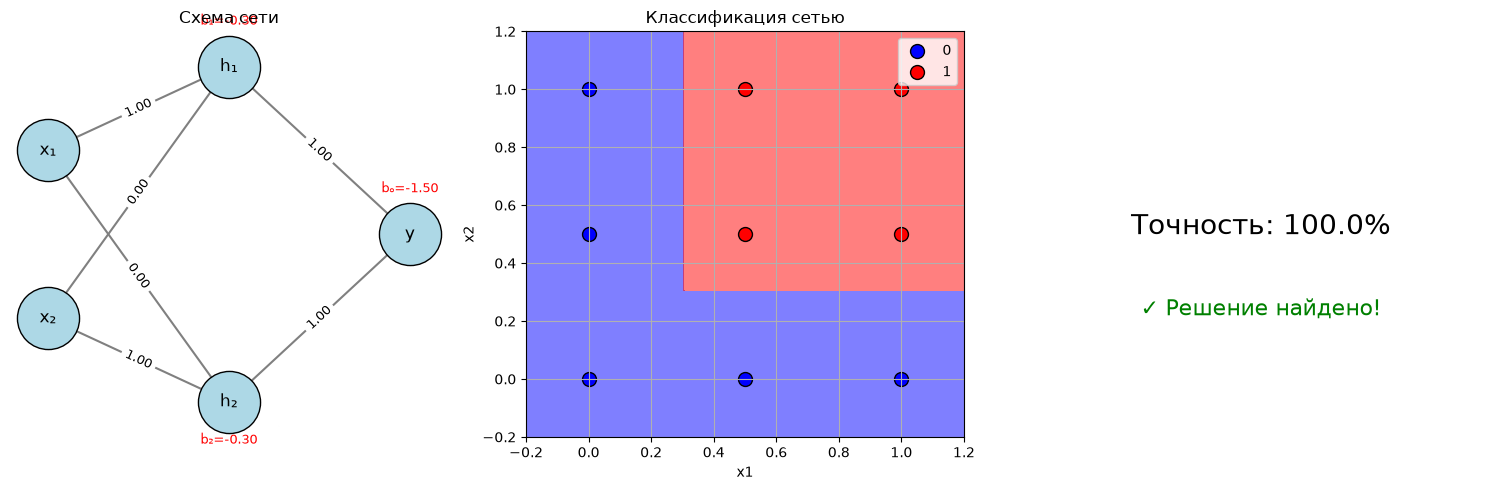

In [11]:
plot_rect_network(**SOL)

**Вопросы для анализа**:
1. Почему один нейрон не может решить эту задачу?
2. Какие функции реализуют скрытые нейроны в правильном решении?
3. Что произойдёт, если изменить вес выходного нейрона на отрицательный?

линейное программирование: решение существует? False | The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is None)
середина отрезка между (0, 1) и (1, 0): [0.5 0.5] -> класс 1

точка        h1=[x1>0.3]  h2=[x2>0.3]  y  (цель)
(0.0, 0.0)        0           0      0  (0)
(0.0, 0.5)        0           1      0  (0)
(0.0, 1.0)        0           1      0  (0)
(0.5, 0.0)        1           0      0  (0)
(0.5, 0.5)        1           1      1  (1)
(0.5, 1.0)        1           1      1  (1)
(1.0, 0.0)        1           0      0  (0)
(1.0, 0.5)        1           1      1  (1)
(1.0, 1.0)        1           1      1  (1)

wo = (-1.0, 1.0), bo = -1.5: выходы [0, 0, 0, 0, 0, 0, 0, 0, 0], точность 56%  — сумма не больше 1 < 1.5: всегда 0
wo = (-1.0, 1.0), bo = -0.5: выходы [0, 1, 1, 0, 0, 0, 0, 0, 0], точность 33%  — h2 И НЕ h1
wo = (-1.0, -1.0), bo = -1.5: выходы [0, 0, 0, 0, 0, 0, 0, 0, 0], точность 56%  — всегда 0
wo = (-1.0, -1.0), bo =  0.5: выходы [1, 0, 

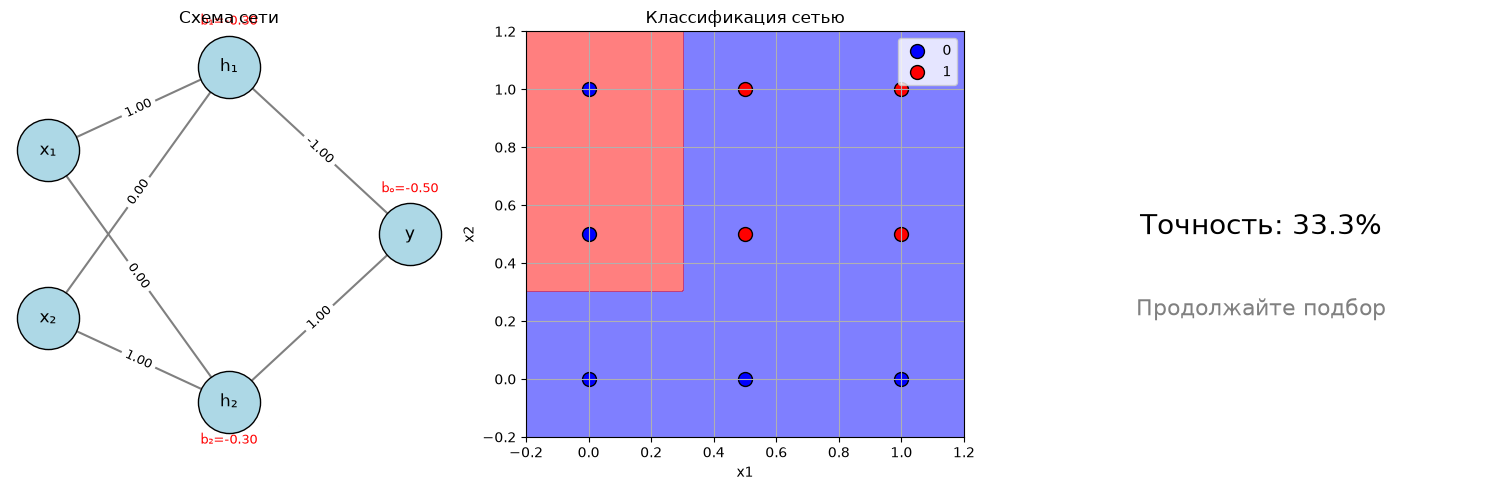

In [12]:
# 1. Один нейрон не справится: ищем w1, w2, b с зазором 1 (линейное программирование) — решения нет
from scipy.optimize import linprog
sgn = np.where(y_rect == 1, 1, -1)
# условие sgn_i * (w1*x1 + w2*x2 + b) >= 1  <=>  -sgn_i * [x1, x2, 1] @ [w1, w2, b] <= -1
A_ub = -sgn[:, None] * np.c_[X_rect, np.ones(len(X_rect))]
lp = linprog(c=[0, 0, 0], A_ub=A_ub, b_ub=-np.ones(len(X_rect)), bounds=[(None, None)] * 3)
print("линейное программирование: решение существует?", lp.success, "|", lp.message)
print("середина отрезка между (0, 1) и (1, 0):", (X_rect[2] + X_rect[6]) / 2, "-> класс", y_rect[4])

# 2. Что реализуют скрытые нейроны
_, a1, a2 = forward_rect(X_rect, np.array([1.0, 0.0]), -0.3, np.array([0.0, 1.0]), -0.3, np.array([1.0, 1.0]), -1.5)
print("\nточка        h1=[x1>0.3]  h2=[x2>0.3]  y  (цель)")
for p, u, v, t in zip(X_rect, a1, a2, y_rect):
    print(f"{str(tuple(p.tolist())):12s} {u:^11d} {v:^11d} {int(u and v)}  ({t})")

# 3. Отрицательный вес выходного нейрона: wo1 = -1 вместо 1
print()
for wo, bo, meaning in [((-1.0, 1.0), -1.5, "сумма не больше 1 < 1.5: всегда 0"),
                        ((-1.0, 1.0), -0.5, "h2 И НЕ h1"),
                        ((-1.0, -1.0), -1.5, "всегда 0"),
                        ((-1.0, -1.0), 0.5, "НЕ h1 И НЕ h2 (ИЛИ-НЕ)")]:
    y_neg, _, _ = forward_rect(X_rect, np.array([1.0, 0.0]), -0.3, np.array([0.0, 1.0]), -0.3, np.array(wo), bo)
    print(f"wo = {wo}, bo = {bo:4}: выходы {y_neg.tolist()}, точность {np.mean(y_neg == y_rect):.0%}  — {meaning}")
plot_rect_network(**{**SOL, "wo1": -1.0, "bo": -0.5})

**1. Один нейрон не справится:** классы нельзя разделить одной прямой. Задача линейного программирования «найти $w_1, w_2, b$, при которых все девять точек лежат по правильную сторону прямой с зазором» не имеет решения (`Infeasible`).

Наглядно: точки (0, 1) и (1, 0) относятся к классу 0, а середина отрезка между ними (0,5; 0,5) — к классу 1. Если обе крайние точки лежат по одну сторону прямой, то и весь отрезок между ними, включая середину, лежит там же. Область класса 1 — угол $x_1 > 0{,}3$, $x_2 > 0{,}3$ — ограничена двумя прямыми, значит, и нейронов нужно два.

**2. Скрытые нейроны реализуют пороговые условия по одной координате.**
- $h_1 = [x_1 - 0{,}3 \ge 0]$ — условие «$x_1 > 0{,}3$», вертикальная прямая $x_1 = 0{,}3$;
- $h_2 = [x_2 - 0{,}3 \ge 0]$ — горизонтальная прямая $x_2 = 0{,}3$.

Каждый скрытый нейрон делит плоскость на две полуплоскости. Выходной нейрон $y = [h_1 + h_2 - 1{,}5 \ge 0]$ реализует логическое И: сумма $h_1 + h_2$ достигает 1,5 только при $h_1 = h_2 = 1$. По таблице в выводе ячейки $y$ совпадает с целью для всех девяти точек. Скрытый слой переводит точки в новое пространство $(h_1, h_2)$, где задача уже линейно разделима. Это та же задача AND, что в задании 2.

**3. Отрицательный вес выходного нейрона меняет логическую функцию**, и сеть перестаёт решать задачу:

| $w_o$ | $b_o$ | что реализует | точность |
|---|---|---|---|
| (−1, 1) | −1,5 | всегда 0: сумма не больше 1 | 56 % (доля класса 0) |
| (−1, 1) | −0,5 | «$h_2$ И НЕ $h_1$» — полоса $x_1 \le 0{,}3$, $x_2 > 0{,}3$ | 33 % |
| (−1, −1) | −1,5 | всегда 0 | 56 % |
| (−1, −1) | 0,5 | «НЕ $h_1$ И НЕ $h_2$» (ИЛИ-НЕ) — угол у начала координат | 44 % |

Отрицательный вес означает, что соответствующее условие *запрещает* срабатывание. Из тех же двух прямых складывается другая область. Чтобы сеть снова решала задачу, весам нужно вернуть положительный знак.

## Заключение

Вы выполнили три задания:
- Настроили нейрон для OR.
- Сравнили поведение разных функций активации на задаче AND.
- Построили двухслойную сеть для нелинейной задачи (прямоугольная область).

Эти упражнения закладывают основу для понимания многослойных сетей и алгоритмов их обучения. Спасибо за работу!